#Dhaka Air Quality 2000–2025: Analysis and Forecasting

In [1]:
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
import statsmodels.api as sm
from copy import deepcopy
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             f1_score, confusion_matrix, roc_auc_score, classification_report, log_loss)

pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

# Palette: fixed categorical order, single-hue sequential, two-hue diverging with a neutral midpoint
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = '#2a78d6','#eb6834','#1baf7a','#eda100','#e87ba4','#008300','#6250d6','#e34948'
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb','#86b6ef','#3987e5','#1c5cab','#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab','#86b6ef','#ecebe7','#f4a27f','#c4471a'])
# Official US EPA AQI category colours (domain convention)
AQI_COLORS = {'Good':'#00e400','Moderate':'#f2d600','Unhealthy for Sensitive Groups':'#ff7e00',
              'Unhealthy':'#ff0000','Very Unhealthy':'#8f3f97','Hazardous':'#7e0023'}

mpl.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11.5,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK2, 'ytick.color': INK2, 'lines.linewidth': 2, 'legend.frameon': False, 'font.size': 9.5,
})
SEASONS = ['Winter', 'Pre-monsoon', 'Monsoon', 'Post-monsoon']
SEASON_COLORS = dict(zip(SEASONS, [BLUE, ORANGE, AQUA, YELLOW]))

## 1. Load and profile

In [2]:
DATA = 'dhaka_air_quality_2000_2025.csv'
raw = pd.read_csv(DATA, parse_dates=['datetime'])
POLL = ['PM2.5', 'PM10', 'O3', 'NO2', 'SO2', 'CO']
MET  = ['Temperature', 'Humidity', 'Wind_Speed', 'Pressure']
NUM  = ['AQI'] + POLL + MET
UNITS = {'AQI':'index','PM2.5':'µg/m³','PM10':'µg/m³','O3':'ppb','NO2':'ppb','SO2':'ppb','CO':'ppm',
         'Temperature':'°C','Humidity':'%','Wind_Speed':'undocumented','Pressure':'hPa (assumed)'}
print(f'{len(raw):,} rows × {raw.shape[1]} columns')
raw.head()

225,816 rows × 12 columns


,datetime,AQI,PM2.5,PM10,O3,NO2,SO2,CO,Temperature,Humidity,Wind_Speed,Pressure
0,2000-01-01 00:00:00,121.861086,44.200712,93.224101,20.586862,15.391414,28.219932,1.049477,20.956667,71.272569,8.375675,1011.742574
1,2000-01-01 01:00:00,99.598077,35.212704,78.893066,22.429471,26.824534,24.385188,0.943859,13.761031,42.616871,10.880553,1010.949986
2,2000-01-01 02:00:00,132.852834,48.575428,118.693959,37.838094,33.403493,28.951413,0.887131,20.216907,59.169387,15.041183,1012.065387
3,2000-01-01 03:00:00,154.588259,64.208516,86.427166,26.747684,12.137395,26.950990,0.793261,18.642574,62.756439,9.904413,1010.162227
4,2000-01-01 04:00:00,114.102260,41.112699,70.193382,33.192759,25.313206,20.741976,1.059887,18.834718,56.369280,14.632070,1007.067421


In [3]:
full_index = pd.date_range(raw.datetime.min(), raw.datetime.max(), freq='h')
checks = pd.Series({
    'Rows': len(raw),
    'Expected hourly timestamps': len(full_index),
    'Missing timestamps': len(full_index.difference(raw.datetime)),
    'Duplicate timestamps': int(raw.datetime.duplicated().sum()),
    'Fully duplicated rows': int(raw.duplicated().sum()),
    'Sorted chronologically': bool(raw.datetime.is_monotonic_increasing),
    'Missing values (all columns)': int(raw[NUM].isna().sum().sum()),
    'Negative values (all columns)': int((raw[NUM] < 0).sum().sum()),
}, name='result').to_frame()
display(checks)

profile = pd.DataFrame({'unit': pd.Series(UNITS), 'missing': raw[NUM].isna().sum(), 'min': raw[NUM].min(),
                        'median': raw[NUM].median(), 'mean': raw[NUM].mean(), 'max': raw[NUM].max(),
                        'std': raw[NUM].std()}).loc[NUM]
profile.round(2)

,result
Rows,225816
Expected hourly timestamps,225816
Missing timestamps,0
Duplicate timestamps,0
Fully duplicated rows,0
Sorted chronologically,True
Missing values (all columns),0
Negative values (all columns),0


,unit,missing,min,median,mean,max,std
AQI,index,0,20.83,171.50,173.88,299.60,47.85
PM2.5,µg/m³,0,5.00,96.30,105.50,250.00,55.88
PM10,µg/m³,0,10.00,164.38,178.67,400.00,95.03
O3,ppb,0,5.00,48.39,50.07,124.49,18.19
NO2,ppb,0,5.00,33.78,34.30,87.30,12.19
SO2,ppb,0,2.00,22.49,23.08,57.27,7.70
CO,ppm,0,0.10,1.61,1.64,3.76,0.54
Temperature,°C,0,10.35,26.07,26.04,40.00,5.14
Humidity,%,0,30.00,69.34,70.02,95.00,10.62
Wind_Speed,undocumented,0,8.00,11.47,13.00,40.00,4.94


## 2. Data-quality audit

### 2.1 Values piled up at hard floors and ceilings

In [4]:
rows = []
for c in NUM:
    lo, hi = raw[c].min(), raw[c].max()
    rows.append({'column': c, 'floor': lo, 'rows at floor': int((raw[c] == lo).sum()),
                 'ceiling': hi, 'rows at ceiling': int((raw[c] == hi).sum())})
cens = pd.DataFrame(rows).set_index('column')
cens['% at floor'] = 100 * cens['rows at floor'] / len(raw)
cens['% at ceiling'] = 100 * cens['rows at ceiling'] / len(raw)
cens.round(3)

,floor,rows at floor,ceiling,rows at ceiling,% at floor,% at ceiling
column,,,,,,
AQI,20.833,685,299.600,5012,0.303,2.220
PM2.5,5.000,685,250.000,5012,0.303,2.220
PM10,10.000,1718,400.000,6534,0.761,2.894
O3,5.000,197,124.493,1,0.087,0.000
NO2,5.000,891,87.303,1,0.395,0.000
SO2,2.000,121,57.272,1,0.054,0.000
CO,0.100,53,3.765,1,0.023,0.000
Temperature,10.346,1,40.000,42,0.000,0.019
Humidity,30.000,1,95.000,2400,0.000,1.063


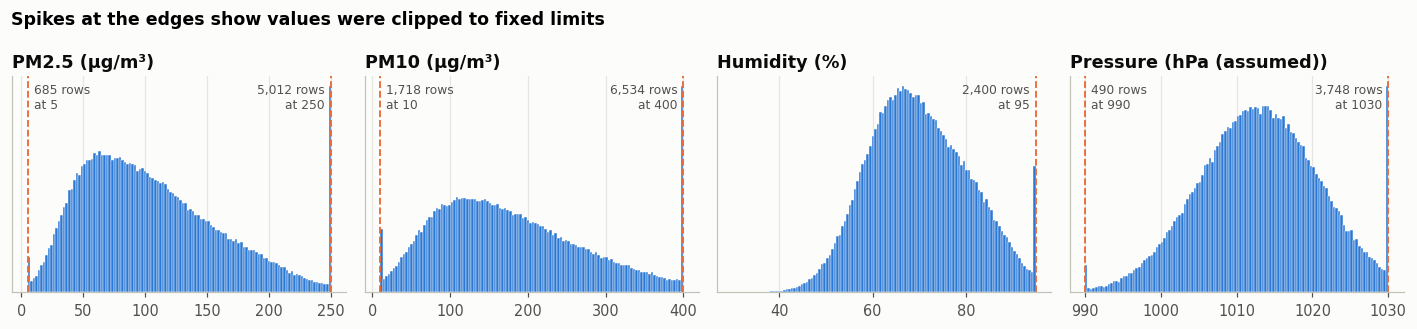

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, c in zip(axes, ['PM2.5', 'PM10', 'Humidity', 'Pressure']):
    ax.hist(raw[c], bins=120, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    for v, side in [(raw[c].min(), 'left'), (raw[c].max(), 'right')]:
        n = (raw[c] == v).sum()
        if n > 50:
            ax.axvline(v, color=ORANGE, lw=1.2, ls='--')
            ax.annotate(f'{n:,} rows\nat {v:g}', xy=(v, ax.get_ylim()[1]*0.85), ha='right' if side=='right' else 'left',
                        fontsize=8, color=INK2, xytext=(-4 if side=='right' else 4, 0), textcoords='offset points')
    ax.set_title(f'{c} ({UNITS[c]})'); ax.set_yticks([])
fig.suptitle('Spikes at the edges show values were clipped to fixed limits', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 2.2 Physical consistency: PM2.5 cannot exceed PM10

In [6]:
bad_pm = raw['PM2.5'] > raw['PM10']
print(f'PM2.5 > PM10 in {bad_pm.sum():,} rows ({100*bad_pm.mean():.2f}%)')
print('Median PM10/PM2.5 ratio in valid rows:', round((raw.loc[~bad_pm, 'PM10'] / raw.loc[~bad_pm, 'PM2.5']).median(), 2))
raw.loc[bad_pm, ['datetime', 'PM2.5', 'PM10']].head()

PM2.5 > PM10 in 4,859 rows (2.15%)
Median PM10/PM2.5 ratio in valid rows: 1.7


,datetime,PM2.5,PM10
18,2000-01-01 18:00:00,38.879639,18.529214
23,2000-01-01 23:00:00,15.915445,10.000000
44,2000-01-02 20:00:00,22.447170,18.657542
49,2000-01-03 01:00:00,10.841066,10.000000
92,2000-01-04 20:00:00,34.094204,30.439272


### 2.3 How AQI is built: it is a function of PM2.5

Correlation (reported AQI, EPA AQI from PM2.5): 0.99998
Mean absolute difference: 0.54 AQI points;  99th pct: 0.99


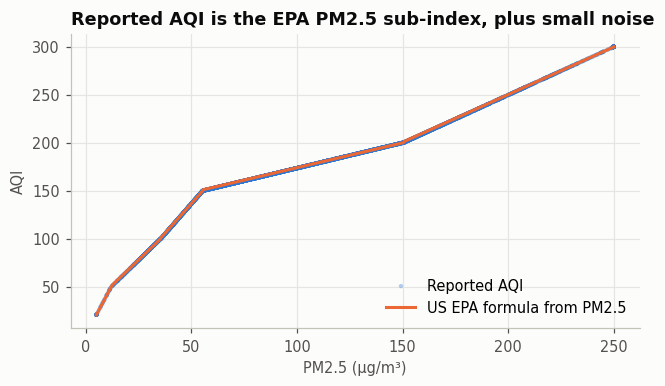

In [7]:
# US EPA PM2.5 breakpoints (pre-2024 revision): (C_lo, C_hi, I_lo, I_hi)
BP = [(0.0, 12.0, 0, 50), (12.1, 35.4, 51, 100), (35.5, 55.4, 101, 150), (55.5, 150.4, 151, 200),
      (150.5, 250.4, 201, 300), (250.5, 350.4, 301, 400), (350.5, 500.4, 401, 500)]
def epa_aqi_pm25(c):
    c = np.asarray(c, float); out = np.empty_like(c)
    his = np.array([b[1] for b in BP]); idx = np.minimum(np.searchsorted(his, c), len(BP) - 1)
    for i, (cl, ch, il, ih) in enumerate(BP):
        m = idx == i; out[m] = (ih - il) / (ch - cl) * (c[m] - cl) + il
    return out

aqi_from_pm = epa_aqi_pm25(raw['PM2.5'])
diff = raw['AQI'] - aqi_from_pm
print(f'Correlation (reported AQI, EPA AQI from PM2.5): {np.corrcoef(raw.AQI, aqi_from_pm)[0,1]:.5f}')
print(f'Mean absolute difference: {diff.abs().mean():.2f} AQI points;  99th pct: {diff.abs().quantile(.99):.2f}')

s = raw.sample(6000, random_state=0)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(s['PM2.5'], s['AQI'], s=8, color=BLUE, alpha=0.35, edgecolor='none', label='Reported AQI')
xx = np.linspace(5, 250, 500); ax.plot(xx, epa_aqi_pm25(xx), color=ORANGE, lw=2, label='US EPA formula from PM2.5')
ax.set_xlabel('PM2.5 (µg/m³)'); ax.set_ylabel('AQI'); ax.legend(loc='lower right')
ax.set_title('Reported AQI is the EPA PM2.5 sub-index, plus small noise')
plt.tight_layout(); plt.show()

### 2.4 Other realism checks

In [8]:
yr = raw.groupby(raw.datetime.dt.year)[['Temperature']].mean().T.round(2)
print('Annual mean temperature (°C):'); display(yr)
print('Correlation of PM2.5 with wind speed:', round(raw['PM2.5'].corr(raw.Wind_Speed), 3),
      '| with pressure:', round(raw['PM2.5'].corr(raw.Pressure), 3),
      '| with humidity:', round(raw['PM2.5'].corr(raw.Humidity), 3))
print('Last timestamp:', raw.datetime.max(), '→ 2025 covers', raw.datetime.dt.year.eq(2025).sum(), 'hours (Jan–early Oct only)')

Annual mean temperature (°C):


datetime,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Temperature,25.97,25.99,26.02,26.02,26.0,26.02,26.0,26.0,25.99,26.01,25.97,25.97,26.0,26.01,26.0,26.02,26.0,25.99,26.01,26.0,25.98,26.01,26.01,26.0,26.0,27.46


Correlation of PM2.5 with wind speed: 0.005 | with pressure: 0.004 | with humidity: -0.085
Last timestamp: 2025-10-04 23:00:00 → 2025 covers 6648 hours (Jan–early Oct only)


## 3. Cleaning and feature engineering

In [9]:
df = raw.set_index('datetime').asfreq('h')          # enforce a regular hourly index (no gaps were found)
assert df[NUM].isna().sum().sum() == 0

PM25_CAP, PM10_CAP = raw['PM2.5'].max(), raw['PM10'].max()

# Flags: keep the information instead of silently dropping or altering rows
df['AQI_capped']       = df['PM2.5'] >= PM25_CAP                 # AQI is a lower bound in these hours
df['PM10_capped']      = df['PM10'] >= PM10_CAP
df['met_clipped']      = ((df.Humidity >= raw.Humidity.max()) | (df.Wind_Speed >= raw.Wind_Speed.max()) |
                          (df.Pressure <= raw.Pressure.min()) | (df.Pressure >= raw.Pressure.max()))
df['PM10_imputed']     = df['PM2.5'] > df['PM10']

# Fix the physically impossible PM10 values: impute with PM2.5 × median PM10/PM2.5 ratio of valid rows in the same month
ratio = (df['PM10'] / df['PM2.5']).where(~df.PM10_imputed)
month_ratio = ratio.groupby(df.index.month).median()
df.loc[df.PM10_imputed, 'PM10'] = (df.loc[df.PM10_imputed, 'PM2.5'] *
                                   df.index[df.PM10_imputed].month.map(month_ratio).values).clip(upper=PM10_CAP)
df['PM10'] = np.maximum(df['PM10'], df['PM2.5'])
assert (df['PM2.5'] <= df['PM10']).all()

# Labels and calendar features
AQI_BINS   = [0, 50, 100, 150, 200, 300, 500]
AQI_LABELS = list(AQI_COLORS)
df['AQI_category'] = pd.cut(df.AQI, bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True)
season_of = {12:'Winter',1:'Winter',2:'Winter',3:'Pre-monsoon',4:'Pre-monsoon',5:'Pre-monsoon',
             6:'Monsoon',7:'Monsoon',8:'Monsoon',9:'Monsoon',10:'Post-monsoon',11:'Post-monsoon'}
df['season']    = pd.Categorical(df.index.month.map(season_of), categories=SEASONS, ordered=True)
df['year']      = df.index.year
df['month']     = df.index.month
df['hour']      = df.index.hour
df['dayofweek'] = df.index.dayofweek
df['weekend']   = df.dayofweek.isin([4, 5])                         # Friday–Saturday weekend in Bangladesh
df['full_year'] = df.year <= 2024

log = pd.DataFrame({
    'issue': ['Missing timestamps / values', 'Duplicates', 'PM2.5 > PM10 (impossible)', 'PM2.5 at 250 cap → AQI censored',
              'PM10 at 400 cap', 'Weather variables clipped', 'Partial final year (2025)'],
    'rows': [0, 0, int(df.PM10_imputed.sum()), int(df.AQI_capped.sum()), int(df.PM10_capped.sum()),
             int(df.met_clipped.sum()), int((df.year == 2025).sum())],
    'action': ['None needed (verified)', 'None needed (verified)', 'PM10 re-imputed from PM2.5 × monthly median ratio; flagged',
               'Kept; flagged AQI_capped (true AQI ≥ value)', 'Kept; flagged', 'Kept; flagged met_clipped',
               'Excluded from annual statistics and trend tests'],
})
log['% of rows'] = (100 * log.rows / len(df)).round(2)
log

,issue,rows,action,% of rows
0,Missing timestamps / values,0,None needed (verified),0.00
1,Duplicates,0,None needed (verified),0.00
2,PM2.5 > PM10 (impossible),4859,PM10 re-imputed from PM2.5 × monthly median ra...,2.15
3,PM2.5 at 250 cap → AQI censored,5012,Kept; flagged AQI_capped (true AQI ≥ value),2.22
4,PM10 at 400 cap,6534,Kept; flagged,2.89
5,Weather variables clipped,6913,Kept; flagged met_clipped,3.06
6,Partial final year (2025),6648,Excluded from annual statistics and trend tests,2.94


In [10]:
out = df.copy(); out[NUM] = out[NUM].round(4)
out.to_csv('dhaka_aq_clean_hourly.csv', index_label='datetime')

daily = df[NUM].resample('D').mean()
daily['AQI_max'] = df['AQI'].resample('D').max()
daily['capped_hours'] = df['AQI_capped'].resample('D').sum()
daily['season'] = daily.index.month.map(season_of)
daily.round(3).to_csv('dhaka_aq_daily.csv', index_label='date')
monthly = df[NUM].resample('MS').mean()
print('Saved dhaka_aq_clean_hourly.csv', out.shape, 'and dhaka_aq_daily.csv', daily.shape)

Saved dhaka_aq_clean_hourly.csv (225816, 23) and dhaka_aq_daily.csv (9409, 14)


## 4. Exploratory visualisation

### 4.1 Long-term trend

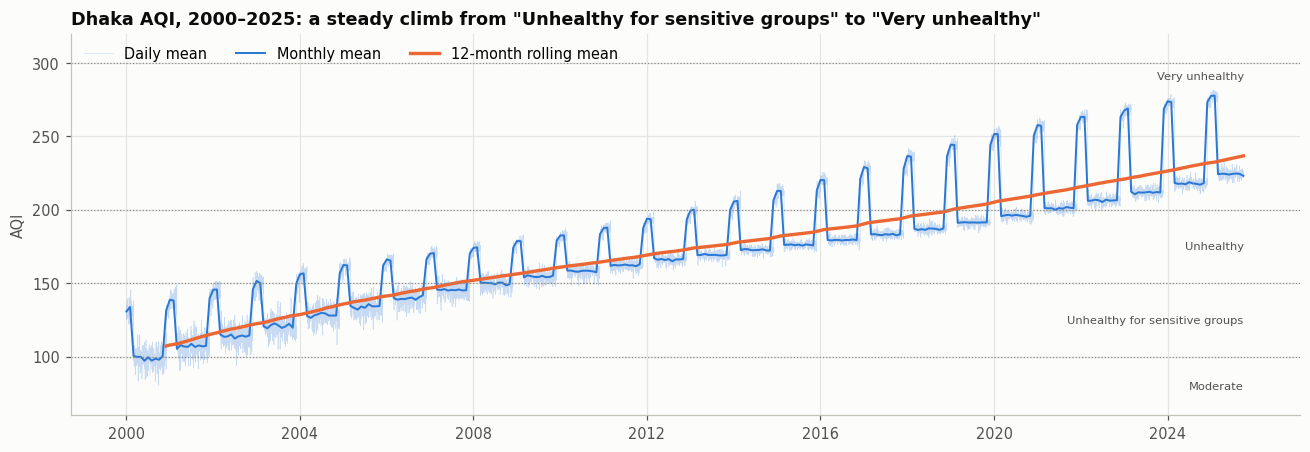

,AQI,pct_unhealthy,pct_very_unhealthy,pct_capped
year,,,,
2000,107.2,19.2,0.0,0.0
2005,140.9,58.7,0.0,0.0
2010,164.2,86.7,3.3,0.0
2015,185.1,98.0,16.2,0.0
2020,209.7,100.0,49.7,5.1
2024,231.7,100.0,68.9,11.9


In [11]:
roll = monthly.AQI.rolling(12).mean()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(daily.index, daily.AQI, color=BLUE, lw=0.4, alpha=0.25, label='Daily mean')
ax.plot(monthly.index, monthly.AQI, color=BLUE, lw=1.3, label='Monthly mean')
ax.plot(roll.index, roll, color=ORANGE, lw=2.2, label='12-month rolling mean')
for y in [100, 150, 200, 300]:
    ax.axhline(y, color=MUTED, lw=0.8, ls=':')
for y, lab in [(80, 'Moderate'), (125, 'Unhealthy for sensitive groups'), (175, 'Unhealthy'), (291, 'Very unhealthy')]:
    ax.text(daily.index[-1], y, lab, fontsize=7.5, color=INK2, ha='right', va='center')
ax.set_ylabel('AQI'); ax.set_ylim(60, 320); ax.legend(loc='upper left', ncol=3)
ax.set_title('Dhaka AQI, 2000–2025: a steady climb from "Unhealthy for sensitive groups" to "Very unhealthy"')
plt.tight_layout(); plt.show()

ann = df.loc[df.full_year].groupby('year').agg(AQI=('AQI', 'mean'), pct_unhealthy=('AQI', lambda s: 100*(s > 150).mean()),
                                               pct_very_unhealthy=('AQI', lambda s: 100*(s > 200).mean()),
                                               pct_capped=('AQI_capped', lambda s: 100*s.mean()))
ann.iloc[[0, 5, 10, 15, 20, 24]].round(1)

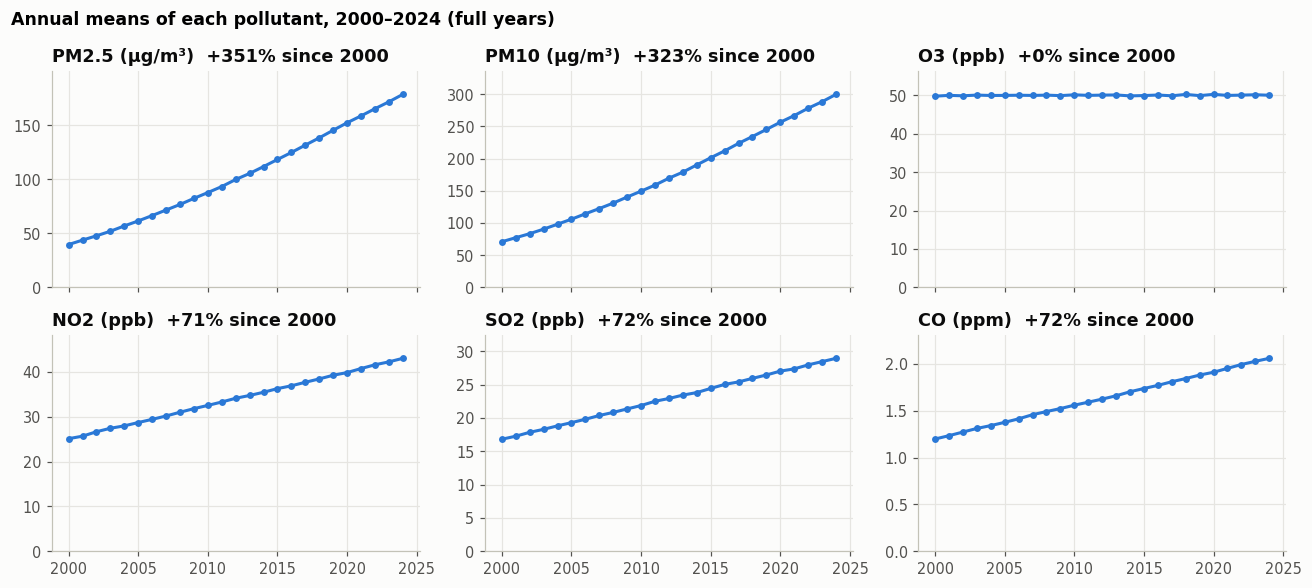

In [12]:
annual = df.loc[df.full_year, NUM].groupby(df.loc[df.full_year].index.year).mean()
fig, axes = plt.subplots(2, 3, figsize=(12, 5.4), sharex=True)
for ax, c in zip(axes.flat, POLL):
    ax.plot(annual.index, annual[c], color=BLUE, marker='o', ms=3.5)
    chg = 100 * (annual[c].iloc[-1] / annual[c].iloc[0] - 1)
    ax.set_title(f'{c} ({UNITS[c]})  {chg:+.0f}% since 2000')
    ax.set_ylim(0, annual[c].max() * 1.12)
fig.suptitle('Annual means of each pollutant, 2000–2024 (full years)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 4.2 Seasonal and diurnal structure

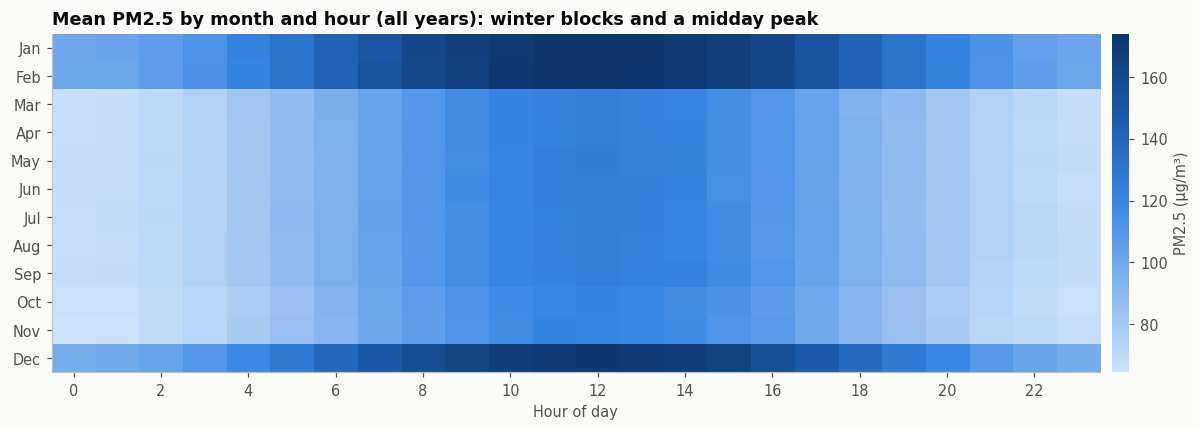

In [13]:
mh = df.pivot_table(index='month', columns='hour', values='PM2.5', aggfunc='mean')
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(mh.values, aspect='auto', cmap=SEQ)
ax.set_yticks(range(12)); ax.set_yticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hour of day'); ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label('PM2.5 (µg/m³)'); cb.outline.set_visible(False)
ax.set_title('Mean PM2.5 by month and hour (all years): winter blocks and a midday peak')
plt.tight_layout(); plt.show()

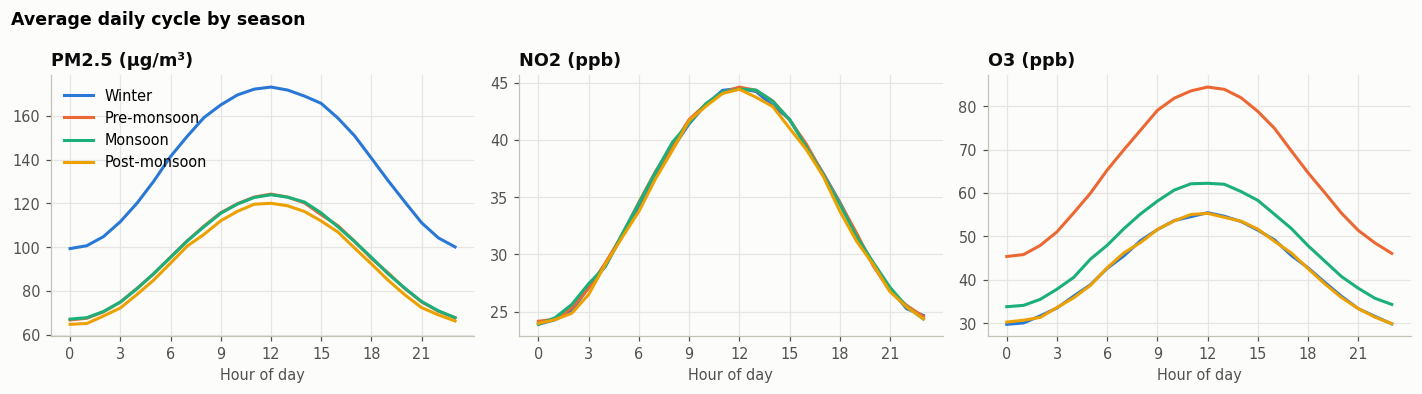

month           1      2     3     4     5     6     7     8     9     10    11     12
PM2.5        139.6  139.6  95.3  95.3  95.4  95.2  95.5  95.4  95.4  92.5  92.4  136.2
Temperature   20.7   22.7  25.5  28.5  30.9  31.9  31.3  29.3  26.4  23.4  21.1   20.1
Humidity      65.0   64.9  65.0  65.0  64.9  79.9  80.0  79.9  80.0  65.1  64.9   65.0


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ['PM2.5', 'NO2', 'O3']):
    prof = df.pivot_table(index='hour', columns='season', values=c, aggfunc='mean', observed=True)
    for sname in SEASONS:
        ax.plot(prof.index, prof[sname], color=SEASON_COLORS[sname], label=sname)
    ax.set_title(f'{c} ({UNITS[c]})'); ax.set_xlabel('Hour of day'); ax.set_xticks(range(0, 24, 3))
axes[0].legend(loc='upper left')
fig.suptitle('Average daily cycle by season', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

print(df.groupby('month')[['PM2.5', 'Temperature', 'Humidity']].mean().round(1).T)

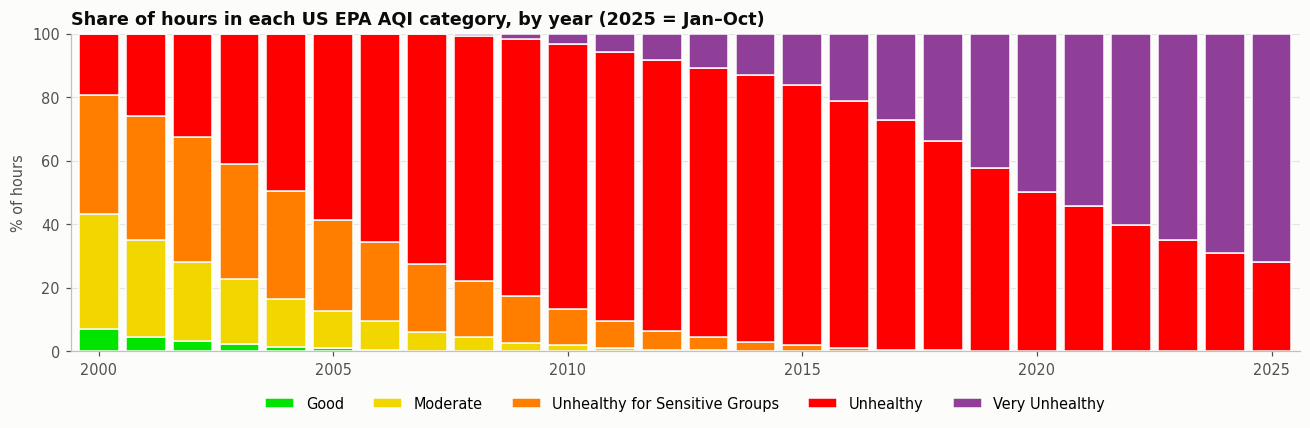

In [15]:
cat_share = (df.groupby('year')['AQI_category'].value_counts(normalize=True).unstack().reindex(columns=AQI_LABELS).fillna(0) * 100)
cats_present = [c for c in AQI_LABELS if cat_share[c].sum() > 0]
fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(cat_share))
for c in cats_present:
    ax.bar(cat_share.index, cat_share[c], bottom=bottom, color=AQI_COLORS[c], edgecolor=SURFACE, linewidth=1, width=0.85, label=c)
    bottom += cat_share[c].values
ax.set_ylabel('% of hours'); ax.set_ylim(0, 100); ax.set_xlim(1999.4, 2025.6)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=len(cats_present))
ax.set_title('Share of hours in each US EPA AQI category, by year (2025 = Jan–Oct)')
plt.tight_layout(); plt.show()

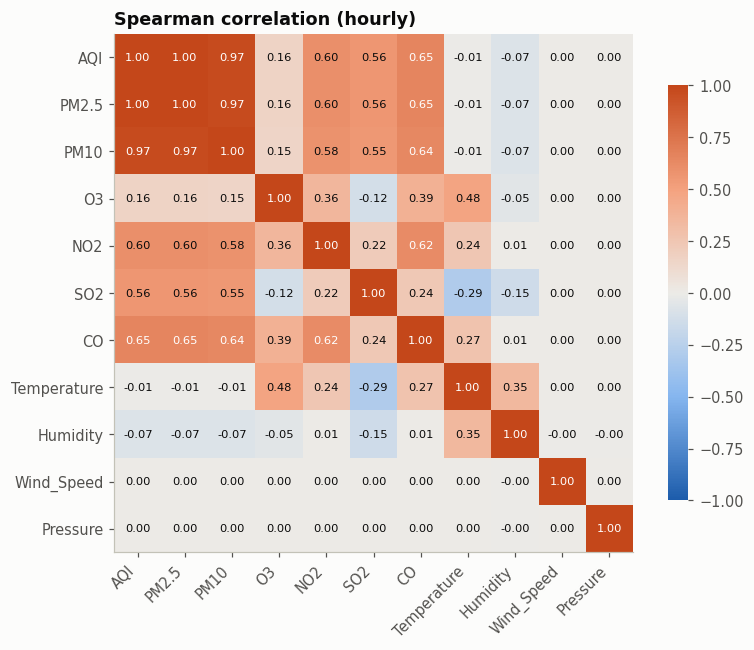

In [16]:
corr = df[NUM].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM))); ax.set_xticklabels(NUM, rotation=45, ha='right'); ax.set_yticks(range(len(NUM))); ax.set_yticklabels(NUM)
for i in range(len(NUM)):
    for j in range(len(NUM)):
        v = corr.iloc[i, j]; ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5, color='white' if abs(v) > 0.6 else INK)
ax.grid(False); cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.outline.set_visible(False)
ax.set_title('Spearman correlation (hourly)')
plt.tight_layout(); plt.show()

## 5. Statistical analysis

### 5.1 Trend significance: Mann–Kendall and Theil–Sen slope

In [17]:
rows = []
for c in NUM:
    tau, p = stats.kendalltau(annual.index, annual[c])
    slope, _, lo, hi = stats.theilslopes(annual[c], annual.index)
    rows.append({'variable': c, 'unit': UNITS[c], '2000': annual[c].iloc[0], '2024': annual[c].iloc[-1],
                 'Sen slope / yr': slope, 'slope 95% CI': f'[{lo:.3f}, {hi:.3f}]',
                 '% of 2000 level / yr': 100 * slope / annual[c].iloc[0], 'Kendall τ': tau, 'p-value': p})
trend = pd.DataFrame(rows).set_index('variable')
trend.style.format({'2000': '{:.2f}', '2024': '{:.2f}', 'Sen slope / yr': '{:.3f}', '% of 2000 level / yr': '{:.2f}',
                    'Kendall τ': '{:.2f}', 'p-value': '{:.1e}'})

,unit,2000,2024,Sen slope / yr,slope 95% CI,% of 2000 level / yr,Kendall τ,p-value
variable,,,,,,,,
AQI,index,107.15,231.67,4.779,"[4.607, 4.993]",4.46,1.00,1.3e-25
PM2.5,µg/m³,39.56,178.42,5.952,"[5.660, 6.243]",15.05,1.00,1.3e-25
PM10,µg/m³,70.84,299.82,9.937,"[9.436, 10.423]",14.03,1.00,1.3e-25
O3,ppb,49.76,50.01,0.006,"[-0.001, 0.014]",0.01,0.24,9.8e-02
NO2,ppb,25.12,43.04,0.748,"[0.743, 0.753]",2.98,1.00,1.3e-25
SO2,ppb,16.82,28.96,0.508,"[0.505, 0.510]",3.02,1.00,1.3e-25
CO,ppm,1.20,2.06,0.036,"[0.036, 0.036]",2.99,1.00,1.3e-25
Temperature,°C,25.97,26.00,0.000,"[-0.001, 0.001]",0.00,0.02,9.1e-01
Humidity,%,69.97,69.99,0.000,"[-0.004, 0.005]",0.00,0.01,9.4e-01


Five of the six pollutants (PM2.5, PM10, NO2, SO2, CO) have a perfectly monotonic upward trend (τ = 1.00, p ≈ 10⁻²⁵). Every year is higher than the last, without exception. PM2.5 rises by about 6 µg/m³ per year (+351 % from 2000 to 2024), and the gases rise by about 70 %. Ozone has no significant trend (τ = 0.24, p ≈ 0.10), and neither does any weather variable. AQI rises more slowly than PM2.5 (about 4.8 points per year, +116 %) because the EPA scale compresses at higher concentrations and the 250 µg/m³ cap starts to bite. A perfect τ = 1 across 25 years is itself a sign of synthetic data, since real series have reversals (e.g. COVID-19 in 2020).

### 5.2 Seasonal and weekend effects (non-parametric tests on detrended daily values)

Kruskal–Wallis across seasons: H = 5,097, p = 0.0e+00, effect size η² = 0.56


,count,25%,median (× annual mean),75%
season,,,,
Winter,2257.0,1.298,1.325,1.352
Pre-monsoon,2300.0,0.871,0.895,0.916
Monsoon,3050.0,0.871,0.895,0.917
Post-monsoon,1525.0,0.872,0.894,0.915


   Pre-monsoon vs Monsoon     : Mann–Whitney p = 0.723  (Bonferroni α = 0.017)
       Monsoon vs Post-monsoon: Mann–Whitney p = 0.38  (Bonferroni α = 0.017)
        Winter vs Pre-monsoon : Mann–Whitney p = 0  (Bonferroni α = 0.017)
Weekend (Fri–Sat) vs weekday: medians 0.909 vs 0.908, Mann–Whitney p = 0.703


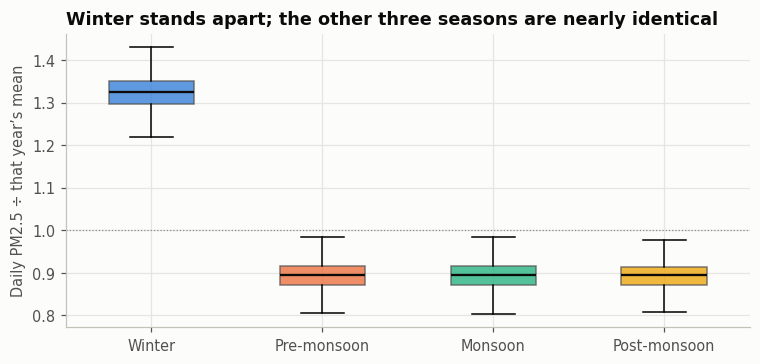

In [18]:
# Divide each day by its year's mean so the strong trend does not confound season comparisons
d = daily.loc[:'2024-12-31', ['PM2.5', 'AQI']].copy()
d['PM2.5_rel'] = d['PM2.5'] / d.groupby(d.index.year)['PM2.5'].transform('mean')
d['season'] = pd.Categorical(d.index.month.map(season_of), categories=SEASONS, ordered=True)
d['weekend'] = d.index.dayofweek.isin([4, 5])

groups = [g['PM2.5_rel'].values for _, g in d.groupby('season', observed=True)]
H, p = stats.kruskal(*groups); k, n = len(groups), len(d)
eta2 = (H - k + 1) / (n - k)
print(f'Kruskal–Wallis across seasons: H = {H:,.0f}, p = {p:.1e}, effect size η² = {eta2:.2f}')
display(d.groupby('season', observed=True)['PM2.5_rel'].describe()[['count', '25%', '50%', '75%']].round(3)
        .rename(columns={'50%': 'median (× annual mean)'}))

pairs = [('Pre-monsoon', 'Monsoon'), ('Monsoon', 'Post-monsoon'), ('Winter', 'Pre-monsoon')]
for a, b in pairs:
    U, pp = stats.mannwhitneyu(d.loc[d.season == a, 'PM2.5_rel'], d.loc[d.season == b, 'PM2.5_rel'])
    print(f'  {a:>12} vs {b:<12}: Mann–Whitney p = {pp:.3g}  (Bonferroni α = {0.05/len(pairs):.3f})')

U, pw = stats.mannwhitneyu(d.loc[d.weekend, 'PM2.5_rel'], d.loc[~d.weekend, 'PM2.5_rel'])
print(f'Weekend (Fri–Sat) vs weekday: medians {d.loc[d.weekend,"PM2.5_rel"].median():.3f} vs '
      f'{d.loc[~d.weekend,"PM2.5_rel"].median():.3f}, Mann–Whitney p = {pw:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.4))
bp = ax.boxplot([d.loc[d.season == s, 'PM2.5_rel'] for s in SEASONS], widths=0.5, patch_artist=True,
                showfliers=False, medianprops=dict(color=INK, lw=1.5))
for patch, s in zip(bp['boxes'], SEASONS): patch.set_facecolor(SEASON_COLORS[s]); patch.set_alpha(0.75); patch.set_edgecolor(INK2)
ax.set_xticklabels(SEASONS)
ax.axhline(1, color=MUTED, lw=0.8, ls=':'); ax.set_ylabel('Daily PM2.5 ÷ that year’s mean')
ax.set_title('Winter stands apart; the other three seasons are nearly identical')
plt.tight_layout(); plt.show()

### 5.3 Decomposition (STL, monthly PM2.5)

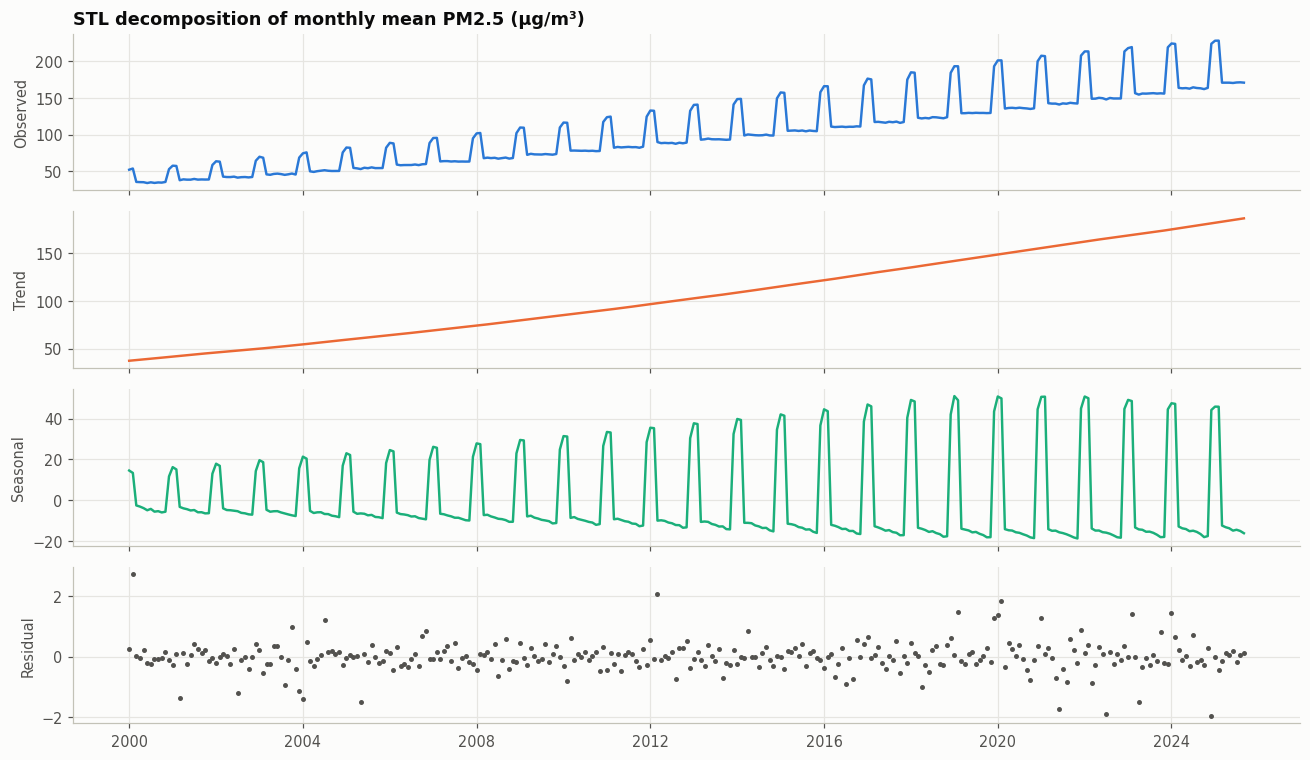

Strength of trend    = 1.000
Strength of seasonal = 0.999


In [19]:
m25 = monthly['PM2.5'].loc[:'2025-09-01']
stl = STL(m25, period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for ax, (s, lab, col) in zip(axes, [(m25, 'Observed', BLUE), (stl.trend, 'Trend', ORANGE), (stl.seasonal, 'Seasonal', AQUA), (stl.resid, 'Residual', INK2)]):
    if lab == 'Residual': ax.scatter(s.index, s, s=5, color=col)
    else: ax.plot(s.index, s, color=col, lw=1.6)
    ax.set_ylabel(lab)
axes[0].set_title('STL decomposition of monthly mean PM2.5 (µg/m³)')
plt.tight_layout(); plt.show()
var = lambda x: np.var(x)
print(f'Strength of trend    = {max(0, 1 - var(stl.resid)/var(stl.trend + stl.resid)):.3f}')
print(f'Strength of seasonal = {max(0, 1 - var(stl.resid)/var(stl.seasonal + stl.resid)):.3f}')

Both components are very strong (strength close to 1). The seasonal component widens over time because the winter excess scales with the overall level, which makes the seasonality multiplicative rather than additive. From about 2019 the winter swing stops growing and then shrinks: winter hours hit the 250 µg/m³ PM2.5 cap, so censoring is now distorting the seasonal pattern.

### 5.4 Stationarity and memory: is there anything left after trend and season?

,series,ADF p (H0: unit root),KPSS p (H0: stationary),verdict
0,Daily AQI (raw),0.0067,0.0100,non-stationary
1,minus linear trend + month dummies,0.0000,0.0517,stationary
2,minus each month’s own mean,0.0000,0.1000,stationary


Memory left in the residual after removing …


,ACF lag 1,ACF lag 2,ACF lag 7,ACF lag 30,Ljung–Box p (lag 7)
linear trend + month dummies,0.718,0.711,0.662,0.462,0.0
each month’s own mean,-0.036,-0.030,-0.037,0.002,0.0


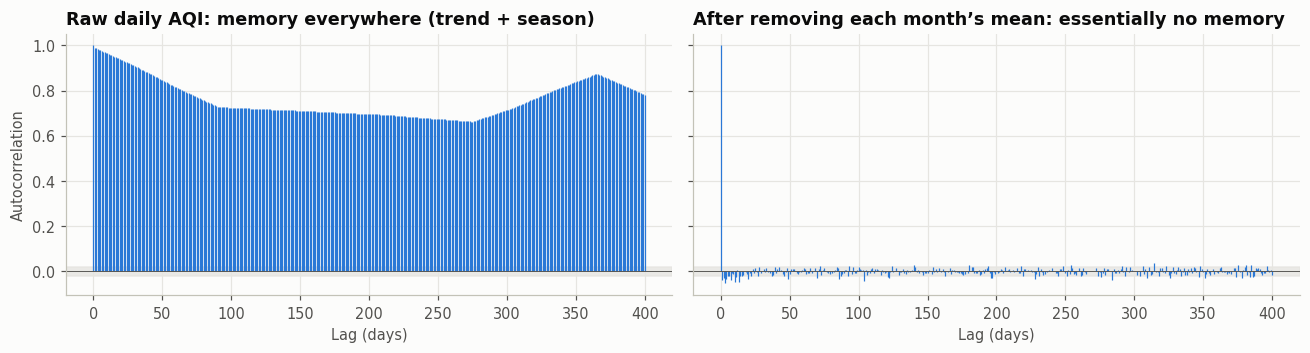

In [20]:
dA = daily['AQI'].loc[:'2025-09-30']

t = np.arange(len(dA)) / 365.25
X = pd.get_dummies(dA.index.month, prefix='m', drop_first=True).astype(float)
X.insert(0, 't', t); X = sm.add_constant(X.set_index(dA.index))
resid_simple = dA - sm.OLS(dA, X).fit().fittedvalues
resid = dA - dA.groupby(dA.index.to_period('M')).transform('mean')

def stationarity(s, name):
    warnings.simplefilter('ignore')
    adf_p = adfuller(s, autolag='AIC')[1]; kpss_p = kpss(s, regression='c', nlags='auto')[1]
    return {'series': name, 'ADF p (H0: unit root)': adf_p, 'KPSS p (H0: stationary)': kpss_p,
            'verdict': 'stationary' if (adf_p < 0.05 and kpss_p > 0.05) else 'non-stationary'}
display(pd.DataFrame([stationarity(dA, 'Daily AQI (raw)'),
                      stationarity(resid_simple, 'minus linear trend + month dummies'),
                      stationarity(resid, 'minus each month’s own mean')]).round(4))

mem = pd.DataFrame({name: {f'ACF lag {L}': pd.Series(r.values).autocorr(L) for L in [1, 2, 7, 30]}
                    for name, r in [('linear trend + month dummies', resid_simple), ('each month’s own mean', resid)]}).T
mem['Ljung–Box p (lag 7)'] = [acorr_ljungbox(r, lags=[7], return_df=True)['lb_pvalue'].iloc[0] for r in [resid_simple, resid]]
print('Memory left in the residual after removing …'); display(mem.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3), sharey=True)
for ax, s, title in [(axes[0], dA, 'Raw daily AQI: memory everywhere (trend + season)'),
                     (axes[1], resid, 'After removing each month’s mean: essentially no memory')]:
    a = acf(s, nlags=400); ci = 1.96 / np.sqrt(len(s))
    ax.vlines(range(len(a)), 0, a, color=BLUE, lw=0.8); ax.axhspan(-ci, ci, color=GRID, alpha=0.8)
    ax.axhline(0, color=INK2, lw=0.6); ax.set_title(title); ax.set_xlabel('Lag (days)')
axes[0].set_ylabel('Autocorrelation')
plt.tight_layout(); plt.show()

This is the most important statistical finding for forecasting. Raw daily AQI is non-stationary, dominated by trend and season. A simple "linear trend + month dummies" fit leaves strong slow structure, because it cannot follow the growing seasonal swing or the saturation near 300. Once each month's own level is removed, the daily residual has practically no memory: every autocorrelation is below 0.04 in size. With about 9,400 days, Ljung–Box still flags these tiny values as statistically detectable, but they are of no practical use, and the small negative values are a mechanical effect of demeaning within ~30-day blocks. Day-to-day deviations do not persist, so a bad day today says almost nothing about tomorrow beyond the month's level and the hour of day. Real pollution episodes last several days because weather systems persist. In this dataset, forecast skill can come only from the trend, season and hour-of-day pattern, and no model can beat that ceiling. The models below are judged against it.

## 6. Forecasting and machine learning

### 6.1. Monthly AQI: classical time-series models

In [21]:
def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p) ** 0.5,
            'MAPE %': 100 * np.mean(np.abs((y - p) / y)), 'R²': r2_score(y, p)}

mA = monthly['AQI'].loc[:'2025-09-01'].asfreq('MS')
train, test = mA[:'2022-12-01'], mA['2023-01-01':]
h = len(test)
preds = {}
preds['Seasonal naïve'] = pd.Series(np.tile(train[-12:].values, int(np.ceil(h / 12)))[:h], index=test.index)
preds['Holt-Winters (add. trend, mult. season)'] = ExponentialSmoothing(train, trend='add', seasonal='mul', seasonal_periods=12).fit().forecast(h)

best = None
warnings.simplefilter('ignore')
for p_ in range(3):
    for q_ in range(3):
        for P_ in range(2):
            for Q_ in range(2):
                try:
                    r = SARIMAX(train, order=(p_, 1, q_), seasonal_order=(P_, 1, Q_, 12)).fit(disp=False)
                    if best is None or r.aic < best[0]: best = (r.aic, (p_, 1, q_), (P_, 1, Q_, 12), r)
                except Exception: pass
sarima_name = f'SARIMA{best[1]}{best[2][:3]}₁₂'
preds[sarima_name] = best[3].get_forecast(h).predicted_mean

def design(idx, t0=train.index[0]):
    X = pd.get_dummies(idx.month, prefix='m', drop_first=True).astype(float)
    X.index = idx
    X.insert(0, 't', (idx.year - t0.year) * 12 + (idx.month - t0.month))
    return sm.add_constant(X, has_constant='add')
ols = sm.OLS(train, design(train.index)).fit()
preds['Regression: linear trend + month dummies'] = ols.predict(design(test.index))

res6a = pd.DataFrame({k: metrics(test, v) for k, v in preds.items()}).T.sort_values('MAE')
print(f'Train: {train.index[0]:%b %Y}–{train.index[-1]:%b %Y} ({len(train)} months) | Test: {test.index[0]:%b %Y}–{test.index[-1]:%b %Y} ({h} months)')
print(f'SARIMA order chosen by AIC: {best[1]} × {best[2]}')
res6a.round(2)

Train: Jan 2000–Dec 2022 (276 months) | Test: Jan 2023–Sep 2025 (33 months)
SARIMA order chosen by AIC: (1, 1, 1) × (1, 1, 1, 12)


,MAE,RMSE,MAPE %,R²
"SARIMA(1, 1, 1)(1, 1, 1)₁₂",1.45,1.89,0.61,0.99
"Holt-Winters (add. trend, mult. season)",2.03,2.41,0.86,0.99
Regression: linear trend + month dummies,6.44,8.71,2.60,0.87
Seasonal naïve,10.76,11.79,4.69,0.76


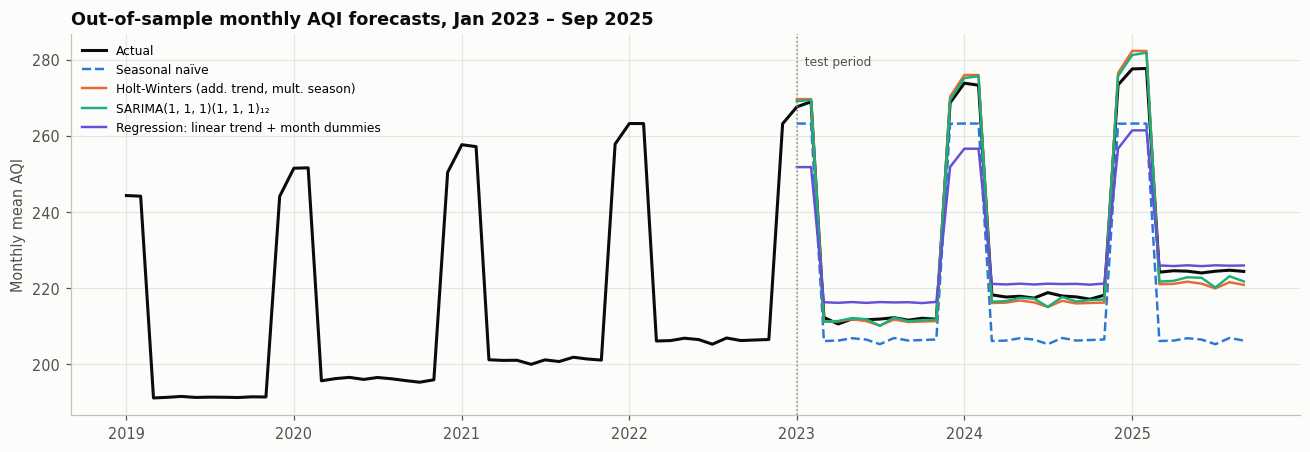

In [22]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(mA['2019-01-01':].index, mA['2019-01-01':], color=INK, lw=2, label='Actual')
cols = [BLUE, ORANGE, AQUA, VIOLET]
for (k, v), c in zip(preds.items(), cols):
    ax.plot(v.index, v, color=c, lw=1.6, ls='--' if 'naïve' in k else '-', label=k)
ax.axvline(test.index[0], color=MUTED, lw=1, ls=':'); ax.text(test.index[0], ax.get_ylim()[1]*0.98, '  test period', color=INK2, fontsize=8, va='top')
ax.set_ylabel('Monthly mean AQI'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('Out-of-sample monthly AQI forecasts, Jan 2023 – Sep 2025')
plt.tight_layout(); plt.show()

Best model on the test period: SARIMA(1, 1, 1)(1, 1, 1)₁₂


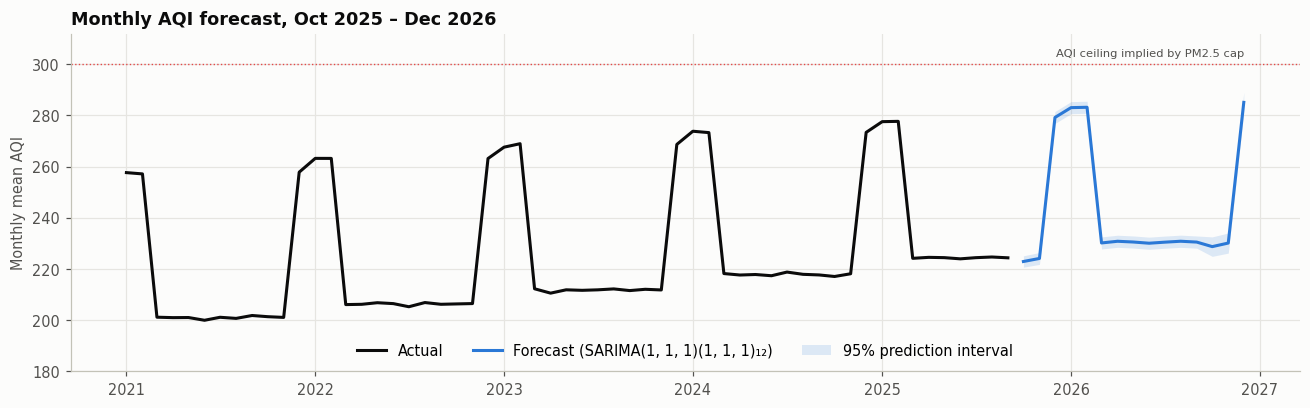

,forecast,lower 95%,upper 95%,note
2025-10-01,222.9,220.7,225.1,
2025-11-01,224.1,221.8,226.4,
2025-12-01,279.2,276.8,281.5,
2026-01-01,283.0,280.7,285.4,
2026-02-01,283.2,280.8,285.5,
2026-03-01,230.2,227.8,232.5,
2026-04-01,230.8,228.5,233.2,
2026-05-01,230.5,228.2,232.9,
2026-06-01,230.1,227.7,232.4,
2026-07-01,230.5,228.1,232.8,


In [23]:
# Refit the best model on all data through Sep 2025 and forecast to Dec 2026
best_name = res6a.index[0]; print('Best model on the test period:', best_name)
horizon = pd.date_range('2025-10-01', '2026-12-01', freq='MS')
if best_name.startswith('Regression'):
    ols_full = sm.OLS(mA, design(mA.index, mA.index[0])).fit()
    fc = ols_full.get_prediction(design(horizon, mA.index[0])).summary_frame(alpha=0.05)
    fc = fc.rename(columns={'mean': 'forecast', 'obs_ci_lower': 'lower 95%', 'obs_ci_upper': 'upper 95%'})[['forecast', 'lower 95%', 'upper 95%']]
elif best_name.startswith('SARIMA'):
    warnings.simplefilter('ignore')
    r = SARIMAX(mA, order=best[1], seasonal_order=best[2]).fit(disp=False).get_forecast(len(horizon))
    ci = r.conf_int(); fc = pd.DataFrame({'forecast': r.predicted_mean, 'lower 95%': ci.iloc[:, 0], 'upper 95%': ci.iloc[:, 1]})
else:
    hw = ExponentialSmoothing(mA, trend='add', seasonal='mul', seasonal_periods=12).fit()
    sim = hw.simulate(len(horizon), repetitions=2000, error='add')
    fc = pd.DataFrame({'forecast': hw.forecast(len(horizon)), 'lower 95%': sim.quantile(.025, axis=1), 'upper 95%': sim.quantile(.975, axis=1)})
fc.index = horizon
fc['note'] = np.where(fc['upper 95%'] > 300, 'interval exceeds AQI ceiling of ~300 (PM2.5 cap)', '')

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(mA['2021-01-01':].index, mA['2021-01-01':], color=INK, lw=2, label='Actual')
ax.plot(fc.index, fc.forecast, color=BLUE, lw=2, label=f'Forecast ({best_name})')
ax.fill_between(fc.index, fc['lower 95%'], fc['upper 95%'], color=BLUE, alpha=0.15, lw=0, label='95% prediction interval')
ax.axhline(300, color=RED, lw=0.9, ls=':'); ax.text(fc.index[-1], 303, 'AQI ceiling implied by PM2.5 cap', fontsize=7.5, color=INK2, ha='right')
ax.set_ylim(180, 312)
ax.set_ylabel('Monthly mean AQI'); ax.legend(loc='lower center', ncol=3); ax.set_title('Monthly AQI forecast, Oct 2025 – Dec 2026')
plt.tight_layout(); plt.show()
fc.round(1)

### 6.2 24-hour-ahead hourly AQI forecasting (gradient boosting, scikit-learn HistGB)

**Task:** predict AQI at hour *t* using only information available at *t − 24 h*. This is a day-ahead forecast for every hour.

**Split:** train 2002–2021, validation 2022 (early stopping), test 1 Jan 2023 – 4 Oct 2025 (about 24,000 hours, never seen in training).

**Leakage control:** no same-hour PM2.5 or PM10, and every lag is at least 24 h.

**Two ways to handle the trend.** Gradient-boosted trees cannot extrapolate beyond target values seen in training, which is a risk when a series keeps rising. Model A uses the raw target and relies on lag and rolling-mean features to carry the current level. Model B predicts the ratio to the trailing 12-month mean, which is a stationary target, and multiplies back. All predictions are clipped to the data's physical range (AQI ≈ 21–300), since the PM2.5 cap makes values above 300 impossible.

In [24]:
y = df['AQI']
F = pd.DataFrame(index=df.index)
F['month'], F['hour'], F['dayofweek'], F['dayofmonth'], F['dayofyear'] = df.month, df.hour, df.dayofweek, df.index.day, df.index.dayofyear
for L in [24, 25, 48, 72, 168]:
    F[f'lag_{L}h'] = y.shift(L)
F['same_hour_7d_mean'] = sum(y.shift(24 * k) for k in range(1, 8)) / 7
F['mean_24h'] = y.shift(24).rolling(24).mean()
F['mean_7d']  = y.shift(24).rolling(168).mean()
F['mean_30d'] = y.shift(24).rolling(720).mean()
F['mean_365d'] = y.shift(24).rolling(8760).mean()
F['last_year_same_period'] = y.shift(8400).rolling(720).mean()        # 30-day window centred on the same date last year
F['NO2_lag24h'], F['CO_lag24h'], F['O3_lag24h'] = df.NO2.shift(24), df.CO.shift(24), df.O3.shift(24)

level = F['mean_365d']
lag_cols = [c for c in F if c.startswith(('lag_', 'same_hour', 'mean_2', 'mean_7', 'mean_30', 'last_year'))]
Fr = F.copy()
for c in lag_cols: Fr[c] = F[c] / level                                 # relative versions for model B
Fr['level_365d'] = level

valid_rows = F.notna().all(axis=1) & (df.index >= '2002-01-01')
tr = valid_rows & (df.index < '2022-01-01'); va = valid_rows & (df.index.year == 2022); te = valid_rows & (df.index >= '2023-01-01')
print(f'train {tr.sum():,} | valid {va.sum():,} | test {te.sum():,} hours')

params = dict(learning_rate=0.03, max_leaf_nodes=63, min_samples_leaf=200,
              l2_regularization=1.0, max_features=0.8, random_state=42)

def fit_es(model, Xtr, ytr, Xva, yva, loss, step=25, patience=4, max_iter=3000):
    """Early stopping on the explicit 2022 validation set (time-ordered, not a random slice of training data)."""
    model.set_params(warm_start=True, early_stopping=False)
    best, best_model, bad = np.inf, None, 0
    for n in range(step, max_iter + 1, step):
        model.set_params(max_iter=n).fit(Xtr, ytr)
        p = model.predict_proba(Xva) if hasattr(model, 'predict_proba') else model.predict(Xva)
        s = loss(yva, p)
        if s < best:
            best, best_model, bad = s, deepcopy(model), 0
        else:
            bad += 1
            if bad >= patience: break
    best_model.best_iteration_ = best_model.n_iter_
    return best_model

feat_A = list(F.columns)
mA_ = fit_es(HistGradientBoostingRegressor(**params), F[tr], y[tr], F[va], y[va], mean_squared_error)
AQI_LO, AQI_HI = raw.AQI.min(), raw.AQI.max()
pred_A = pd.Series(np.clip(mA_.predict(F[te]), AQI_LO, AQI_HI), index=y[te].index)

feat_B = list(Fr.columns)
yB = y / level
mB_ = fit_es(HistGradientBoostingRegressor(**params), Fr[tr], yB[tr], Fr[va], yB[va], mean_squared_error)
pred_B = pd.Series(np.clip(mB_.predict(Fr[te]) * level[te], AQI_LO, AQI_HI), index=y[te].index)
print('Best iterations: A =', mA_.best_iteration_, '| B =', mB_.best_iteration_)

train 175,320 | valid 8,760 | test 24,192 hours
Best iterations: A = 1075 | B = 550


In [25]:
yt = y[te]
# Oracle: the true month-of-that-year × hour mean on the test data itself (uses the future; an approximate ceiling on skill)
oracle = df.loc[te].groupby([df.loc[te].index.to_period('M'), 'hour'])['AQI'].transform('mean')

def to_cat(v): return pd.cut(np.clip(v, 0, 500), bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True)
cands = {'Persistence (same hour yesterday)': F.loc[te, 'lag_24h'],
         'Same hour, mean of last 7 days': F.loc[te, 'same_hour_7d_mean'],
         'HistGB A: raw target': pred_A,
         'HistGB B: ratio-to-trend target': pred_B,
         'Oracle month×hour profile (uses future, ceiling)': oracle}
res6b = pd.DataFrame({k: {**metrics(yt, v), 'category accuracy %': 100 * (to_cat(v).astype(str) == df.loc[te, 'AQI_category'].astype(str)).mean()}
                      for k, v in cands.items()}).T
print(f'Test-period AQI std = {yt.std():.1f}')
res6b.round(2)

Test-period AQI std = 39.7


,MAE,RMSE,MAPE %,R²,category accuracy %
Persistence (same hour yesterday),12.69,17.46,5.66,0.81,89.68
"Same hour, mean of last 7 days",10.27,14.51,4.57,0.87,91.75
HistGB A: raw target,9.71,12.98,4.26,0.89,92.60
HistGB B: ratio-to-trend target,10.01,13.25,4.49,0.89,91.42
"Oracle month×hour profile (uses future, ceiling)",8.68,11.76,3.87,0.91,93.08


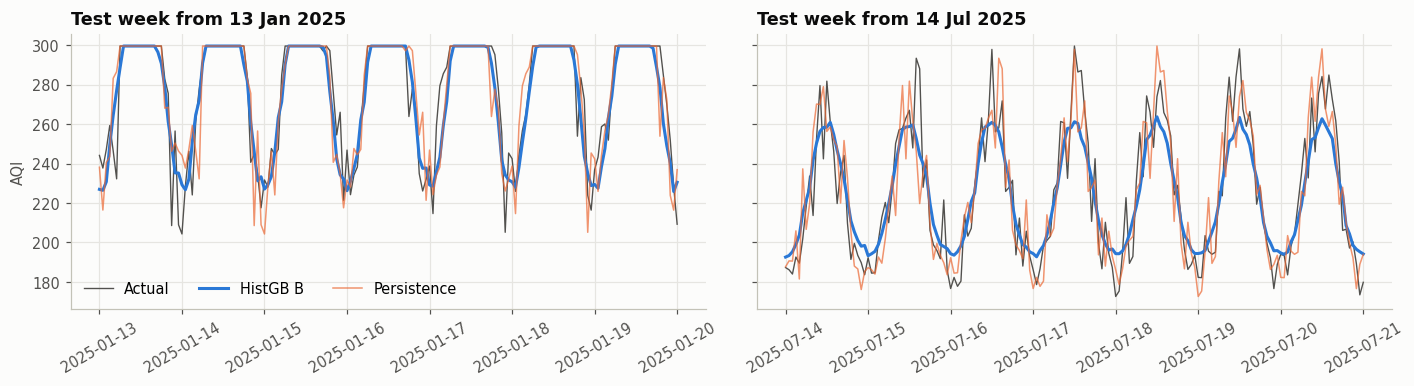

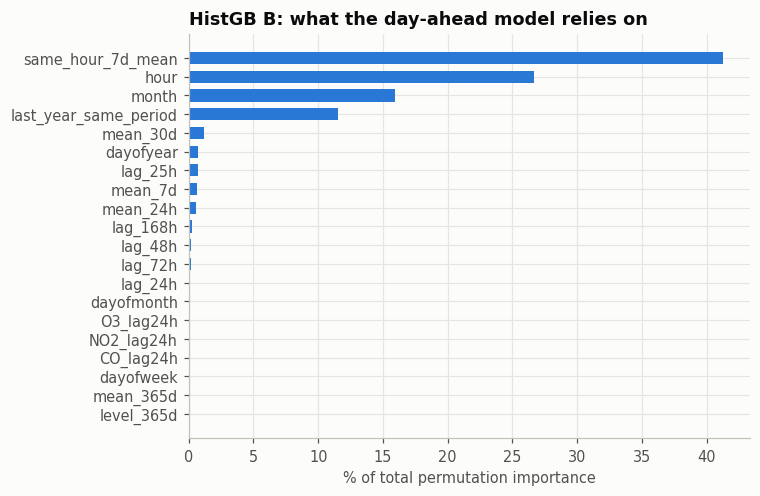

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, start in zip(axes, ['2025-01-13', '2025-07-14']):
    sl = slice(start, pd.Timestamp(start) + pd.Timedelta(days=7))
    ax.plot(yt[sl].index, yt[sl], color=INK2, lw=0.9, label='Actual')
    ax.plot(pred_B[sl].index, pred_B[sl], color=BLUE, lw=2, label='HistGB B')
    ax.plot(F.loc[te, 'lag_24h'][sl].index, F.loc[te, 'lag_24h'][sl], color=ORANGE, lw=1, alpha=0.7, label='Persistence')
    ax.set_title(f'Test week from {pd.Timestamp(start):%d %b %Y}'); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('AQI'); axes[0].legend(loc='lower left', ncol=3)
plt.tight_layout(); plt.show()

pi = permutation_importance(mB_, Fr[va], yB[va], n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=feat_B).clip(lower=0).sort_values()
imp = 100 * imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp.index, imp.values, color=BLUE, height=0.65); ax.set_xlabel('% of total permutation importance')
ax.set_title('HistGB B: what the day-ahead model relies on')
plt.tight_layout(); plt.show()

**Reading the result:** the models learn the hour-of-day and calendar profile, which is all the signal there is. Hourly AQI keeps roughly ±19 points of unpredictable noise, so even the oracle that knows each test month's true hourly profile is only modestly better. Persistence does *worse* than a 7-day same-hour average, because yesterday's hour carries yesterday's noise. Without clipping, model B's winter predictions overshot 300, as the test-week plot shows. Clipping fixes that, and the comparison above is made after clipping.

### 6.3 AQI health-category classification 

Test-set class counts: {'Very Unhealthy': 16530, 'Unhealthy': 7660, 'Unhealthy for Sensitive Groups': 2} → scored on ['Unhealthy', 'Very Unhealthy']


,accuracy %,macro-F1,ROC-AUC (Very Unhealthy vs rest)
Persistence category,89.683,0.881,NaN
Category of HistGB A regression,92.601,0.914,NaN
HistGB classifier (balanced),92.068,0.911,0.974
"Oracle profile category (uses future, ceiling)",93.084,0.919,NaN


                precision    recall  f1-score   support

     Unhealthy      0.842     0.922     0.880      7660
Very Unhealthy      0.962     0.920     0.941     16530

     micro avg      0.921     0.921     0.921     24190
     macro avg      0.902     0.921     0.911     24190
  weighted avg      0.924     0.921     0.922     24190



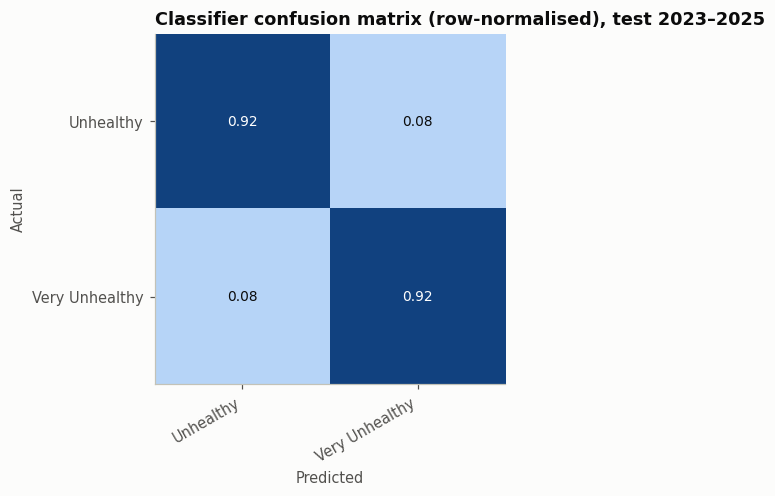

In [27]:
cat_train = df.loc[tr, 'AQI_category'].astype(str); cat_val = df.loc[va, 'AQI_category'].astype(str); cat_test = df.loc[te, 'AQI_category'].astype(str)
classes = [c for c in AQI_LABELS if c in set(cat_train)]
cmap_idx = {c: i for i, c in enumerate(classes)}
k = list(range(len(classes)))
clf = fit_es(HistGradientBoostingClassifier(**params, class_weight='balanced'),
             Fr[tr], cat_train.map(cmap_idx), Fr[va], cat_val.map(cmap_idx),
             lambda a, p: log_loss(a, p, labels=k), max_iter=2000)
proba = clf.predict_proba(Fr[te])
pred_cls = pd.Series(np.array(classes)[proba.argmax(1)], index=cat_test.index)

test_counts = cat_test.value_counts()
test_classes = [c for c in classes if test_counts.get(c, 0) >= 50]       # score classes with meaningful support
print('Test-set class counts:', test_counts.to_dict(), '→ scored on', test_classes)
summ = {}
for name, p in {'Persistence category': to_cat(F.loc[te, 'lag_24h']).astype(str),
                'Category of HistGB A regression': to_cat(pred_A).astype(str),
                'HistGB classifier (balanced)': pred_cls,
                'Oracle profile category (uses future, ceiling)': to_cat(oracle).astype(str)}.items():
    summ[name] = {'accuracy %': 100 * accuracy_score(cat_test, p), 'macro-F1': f1_score(cat_test, p, labels=test_classes, average='macro')}
vu = classes.index('Very Unhealthy')
summ['HistGB classifier (balanced)']['ROC-AUC (Very Unhealthy vs rest)'] = roc_auc_score(cat_test == 'Very Unhealthy', proba[:, vu])
display(pd.DataFrame(summ).T.round(3))
print(classification_report(cat_test, pred_cls, labels=test_classes, digits=3, zero_division=0))
keep = cat_test.isin(test_classes)

cm = confusion_matrix(cat_test[keep], pred_cls[keep], labels=test_classes, normalize='true')
short = {'Unhealthy for Sensitive Groups': 'USG'}
lbl = [short.get(c, c) for c in test_classes]
fig, ax = plt.subplots(figsize=(5.8, 4.6))
im = ax.imshow(cm, cmap=SEQ, vmin=0, vmax=1)
for i in range(len(lbl)):
    for j in range(len(lbl)):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.5 else INK, fontsize=9)
ax.set_xticks(range(len(lbl))); ax.set_xticklabels(lbl, rotation=30, ha='right'); ax.set_yticks(range(len(lbl))); ax.set_yticklabels(lbl)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.grid(False)
ax.set_title('Classifier confusion matrix (row-normalised), test 2023–2025')
plt.tight_layout(); plt.show()

### 6.4 PM2.5 gap-filling from co-pollutants and weather

**Use case:** a PM2.5 monitor goes offline while the gas analysers and weather sensors keep running. How well can PM2.5 be reconstructed? Gap-filling inside the record is interpolation rather than forecasting, so a blocked random split by week is appropriate here (20 % of weeks held out). It avoids the leakage that a row-level random split would cause.

In [ ]:
G = df[['NO2', 'SO2', 'CO', 'O3'] + MET].copy()
G['hour'], G['month'] = df.hour, df.month
G['year_frac'] = df.year + (df.index.dayofyear - 1) / 365.25
target = df['PM2.5']
weeks = df.index.to_period('W')
rng = np.random.default_rng(7); uw = weeks.unique()
test_weeks = set(rng.choice(uw, size=int(0.2 * len(uw)), replace=False))
is_test = np.array([w in test_weeks for w in weeks])

feature_sets = {'Weather only': MET,
                'Calendar only (hour, month, year)': ['hour', 'month', 'year_frac'],
                'Gases + weather (no calendar)': ['NO2', 'SO2', 'CO', 'O3'] + MET,
                'Calendar + gases + weather': list(G.columns)}
gp = dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=100,
          max_features=0.9, early_stopping=False, random_state=42)
res6d, models6d = {}, {}
for name, cols in feature_sets.items():
    m = HistGradientBoostingRegressor(**gp).fit(G.loc[~is_test, cols], target[~is_test])
    p = m.predict(G.loc[is_test, cols]); models6d[name] = m
    res6d[name] = metrics(target[is_test], p)
display(pd.DataFrame(res6d).T.drop(columns='MAPE %').round(3))

full = models6d['Calendar + gases + weather']
pi = permutation_importance(full, G.loc[is_test], target[is_test], n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=G.columns).clip(lower=0).sort_values(); imp = 100 * imp / imp.sum()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(imp.index, imp.values, color=BLUE, height=0.65); ax.set_xlabel('% of total permutation importance')
ax.set_title('PM2.5 gap-filling model: feature importance')
plt.tight_layout(); plt.show()

## 7. Conclusions

### Key findings

**Data quality.** The file is structurally perfect (no gaps, missing values or duplicates) but not clean:
* 2.2 % of hours have PM2.5 censored at 250 µg/m³, which caps AQI at about 300. The share of capped hours rises from 0 % in 2000 to 11.9 % in 2024, so censoring increasingly distorts recent winters.
* 2.2 % of rows had PM2.5 > PM10, which is physically impossible. PM10 was re-imputed and the rows flagged.
* 3.1 % of rows have clipped weather values (flagged), and 2025 is a partial year (excluded from annual statistics).
* AQI is the US EPA PM2.5 sub-index (r = 0.99998). Using same-hour PM2.5 or PM10 to "predict" AQI is leakage, and "Hazardous" can never occur.

**Patterns.**
* Annual mean AQI rose from 107 (2000) to 232 (2024). The share of hours above 150 ("Unhealthy") went from 19 % to 100 %, and above 200 ("Very Unhealthy") from 0 % to 69 %. PM2.5 rose by 351 %. NO2, SO2 and CO rose by about 70 %, and ozone was flat.
* Winter (Dec–Feb) runs about 1.33 × the annual mean. The other three seasons are statistically indistinguishable at about 0.89 × (pre-monsoon vs monsoon p = 0.72). There is no weekend effect (p = 0.70), and every pollutant peaks around noon.

**Predictability.** Once each month's level is removed, day-to-day deviations have practically no memory (|ACF| < 0.04). Forecast skill therefore comes almost entirely from trend + month + hour of day.

**Model results**

| Task | Best model | Result | Reference points |
|---|---|---|---|
| Monthly AQI, 33-month test (Jan 2023 – Sep 2025) | SARIMA(1,1,1)(1,1,1)₁₂ | MAE 1.45 AQI, MAPE 0.6 % | Holt-Winters 2.03 · trend + month dummies 6.44 · seasonal naïve 10.76 |
| Hourly AQI, 24 h ahead (2023–2025) | HistGB (raw target) | MAE 9.8, R² 0.89 | persistence 12.7 · 7-day same-hour mean 10.3 · oracle profile 8.7 |
| AQI category, 24 h ahead | HistGB regression output cut into categories | 92.7 % accuracy | direct HistGB classifier 91.9 % (macro-F1 0.91, ROC-AUC 0.97 for Very Unhealthy) · persistence 89.7 % · oracle 93.1 % |
| PM2.5 gap-filling (held-out weeks) | Calendar-only HistGB | R² 0.926, MAE 11.8 µg/m³ | + gases & weather 0.925 · gases + weather 0.69 · weather only 0.01 |

* The day-ahead model captures about 70 % of the achievable improvement over persistence; the rest is irreducible hourly noise. The 7-day same-hour average is a strong, nearly free baseline.
* For health categories, cutting a good regression forecast into categories slightly beats training a separate classifier. The categories are just thresholds on the same quantity, and test hours fall almost entirely into two classes (Unhealthy and Very Unhealthy).
* The 2026 forecast puts winter 2025–26 monthly means at about 280–283 and the rest of 2026 at about 230. The 95 % intervals are only about ±3 AQI because the generator is so regular. Real-world intervals would be far wider, and winter values are pinned below the ~300 ceiling.
* For gap-filling, co-pollutants and weather add nothing beyond the calendar. The gases score R² 0.69 only because they share PM2.5's trend and seasonal shape, and weather carries no signal at all.